# Netflix Customer Intelligence – Exploratory Data Analysis (EDA)

## Project Overview

This notebook performs Exploratory Data Analysis (EDA) on the cleaned Netflix customer datasets.

## Objectives

1. Understand the structure of all nine datasets.
2. Analyze customer demographics and subscription patterns.
3. Explore viewing behavior and content preferences.
4. Analyze payment trends and customer feedback.
5. Investigate customer churn patterns.
6. Identify meaningful business insights through visualizations.

## Data Source

The cleaned datasets are stored in `data/processed/final/`.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

In [3]:
project_root = Path.cwd().parent

final_data_path = project_root / "data" / "processed" / "final"

print("Final data folder exists:", final_data_path.exists())

Final data folder exists: True


In [4]:
cleaned_datasets = {
    "customers": pd.read_csv(final_data_path / "customers_final.csv"),
    "subscription_plans": pd.read_csv(final_data_path / "subscription_plans_final.csv"),
    "content": pd.read_csv(final_data_path / "content_final.csv"),
    "subscriptions": pd.read_csv(final_data_path / "subscriptions_final1.csv"),
    "viewing_activity": pd.read_csv(final_data_path / "viewing_activity_final.csv"),
    "payments": pd.read_csv(final_data_path / "payments_final1.csv"),
    "support_tickets": pd.read_csv(final_data_path / "support_tickets_final1.csv"),
    "customer_feedback": pd.read_csv(final_data_path / "customer_feedback_final1.csv"),
    "churn_labels": pd.read_csv(final_data_path / "churn_labels_final.csv")
}

print("All nine cleaned datasets loaded successfully!")

All nine cleaned datasets loaded successfully!


In [5]:
for name, df in cleaned_datasets.items():
    print(f"{name}: {df.shape}")

customers: (8000, 12)
subscription_plans: (3, 6)
content: (500, 9)
subscriptions: (8875, 10)
viewing_activity: (66422, 9)
payments: (110735, 8)
support_tickets: (6120, 11)
customer_feedback: (5046, 6)
churn_labels: (8000, 4)


In [6]:
# Data quality overview
dataset_summary = []

for name, df in cleaned_datasets.items():
    dataset_summary.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum()
    })

summary_df = pd.DataFrame(dataset_summary)

display(summary_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows
0,customers,8000,12,8000,0
1,subscription_plans,3,6,0,0
2,content,500,9,0,0
3,subscriptions,8875,10,19819,0
4,viewing_activity,66422,9,0,0
5,payments,110735,8,104574,0
6,support_tickets,6120,11,3117,0
7,customer_feedback,5046,6,0,0
8,churn_labels,8000,4,12018,0


In [7]:
# Missing values Analysis
for name, df in cleaned_datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        missing_summary = pd.DataFrame({
            "Missing Count": missing,
            "Missing Percentage": (missing / len(df) * 100).round(2)
        })

        print(f"\n{name.upper()}")
        display(missing_summary)


CUSTOMERS


,Missing Count,Missing Percentage
state_or_region,8000,100.0



SUBSCRIPTIONS


,Missing Count,Missing Percentage
subscription_end_date,6051,68.18
cancellation_date,6884,77.57
cancellation_reason,6884,77.57



PAYMENTS


,Missing Count,Missing Percentage
subscription_id,1045,0.94
failed_payment_reason,103529,93.49



SUPPORT_TICKETS


,Missing Count,Missing Percentage
ticket_date,61,1.00
resolution_time_hours,1528,24.97
customer_satisfaction_score,1528,24.97



CHURN_LABELS


,Missing Count,Missing Percentage
churn_date,6009,75.11
churn_reason,6009,75.11


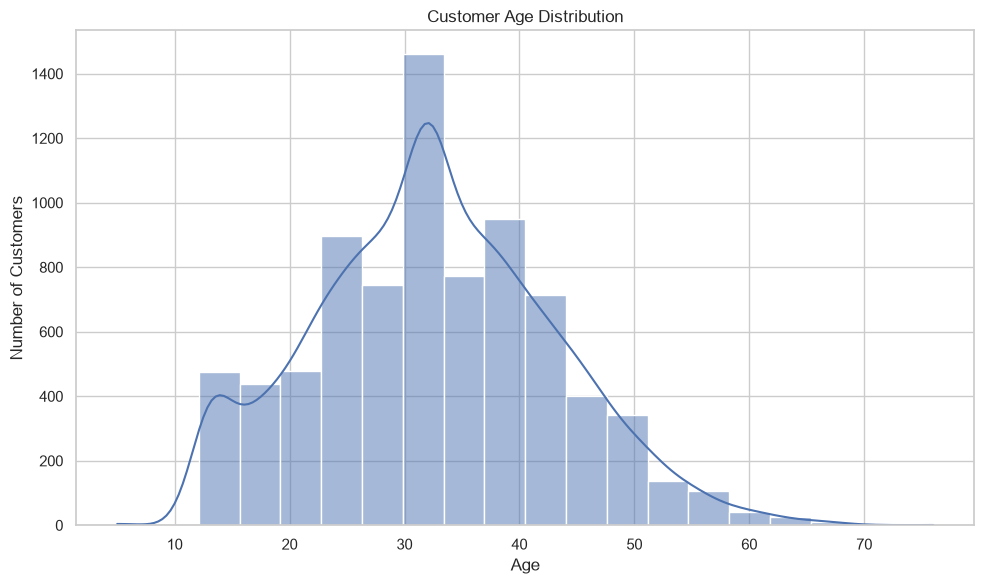

In [8]:
# Visualization 1: customer age distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=cleaned_datasets["customers"],
    x="age",
    bins=20,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

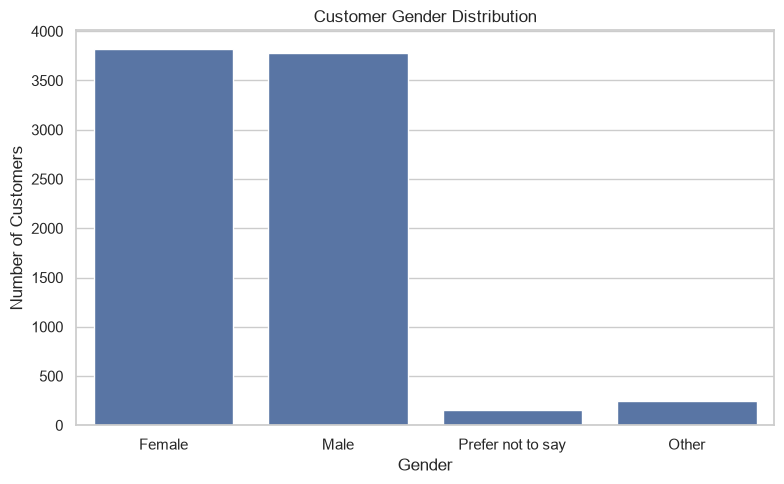

In [ ]:
# Visualization 2: customer gender distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cleaned_datasets["customers"],
    x="gender"
)

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

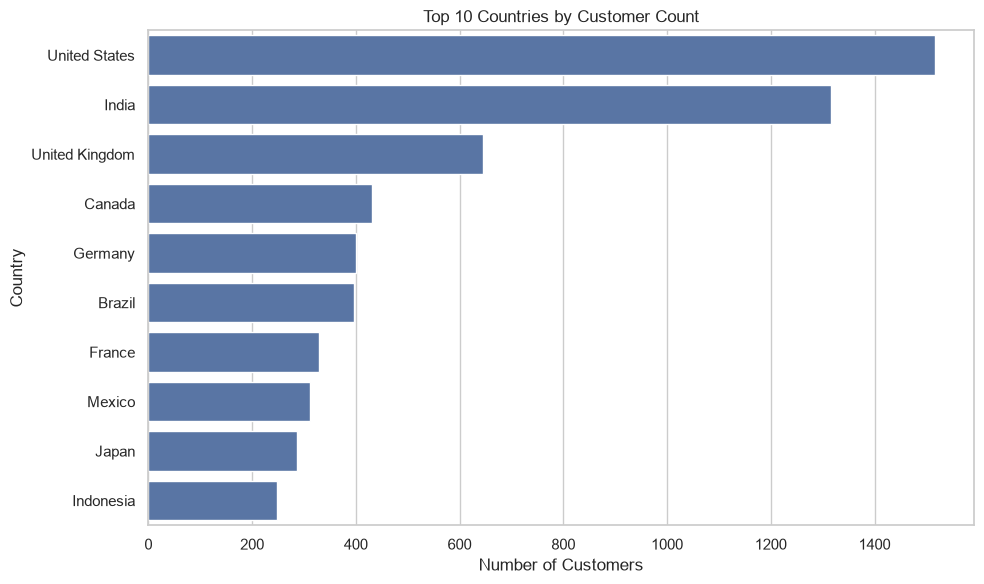

In [ ]:
# Visualization 3: top 10 countries by customer count
country_counts = (
    cleaned_datasets["customers"]["country"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index
)

plt.title("Top 10 Countries by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

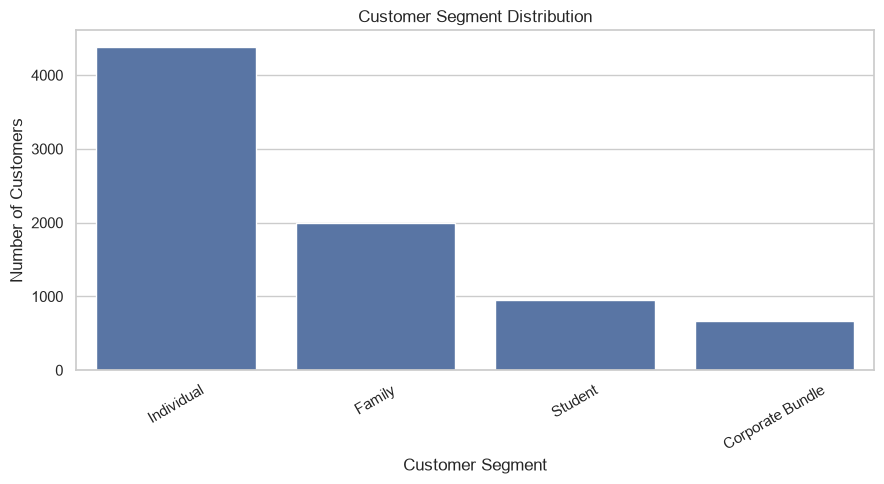

In [ ]:
# Visualization 4: customer segment distribution
segment_counts = cleaned_datasets["customers"]["customer_segment"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

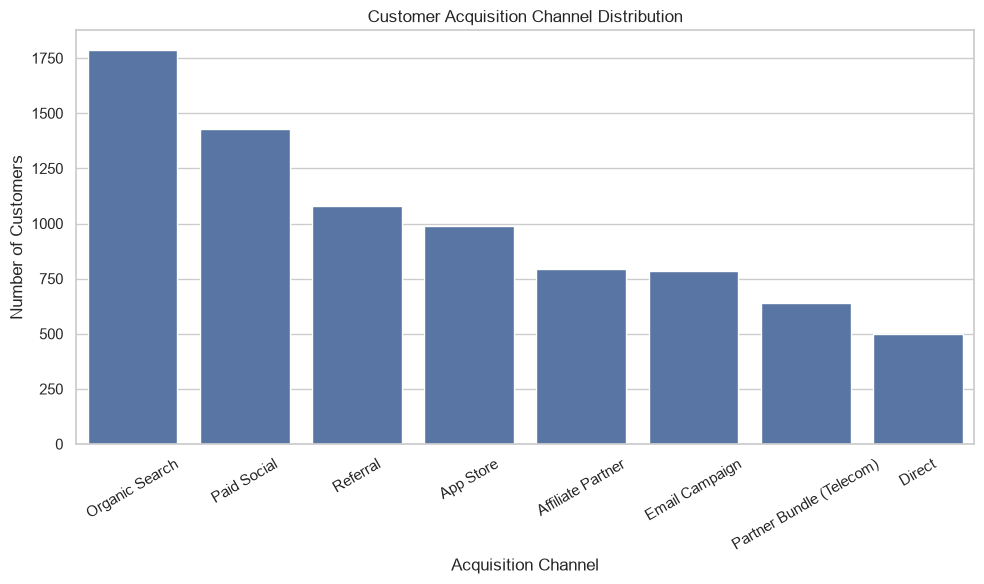

In [12]:
# Visualization 5 – Customer Acquisition Channel Distribution.
channel_counts = cleaned_datasets["customers"]["acquisition_channel"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=channel_counts.index,
    y=channel_counts.values
)

plt.title("Customer Acquisition Channel Distribution")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

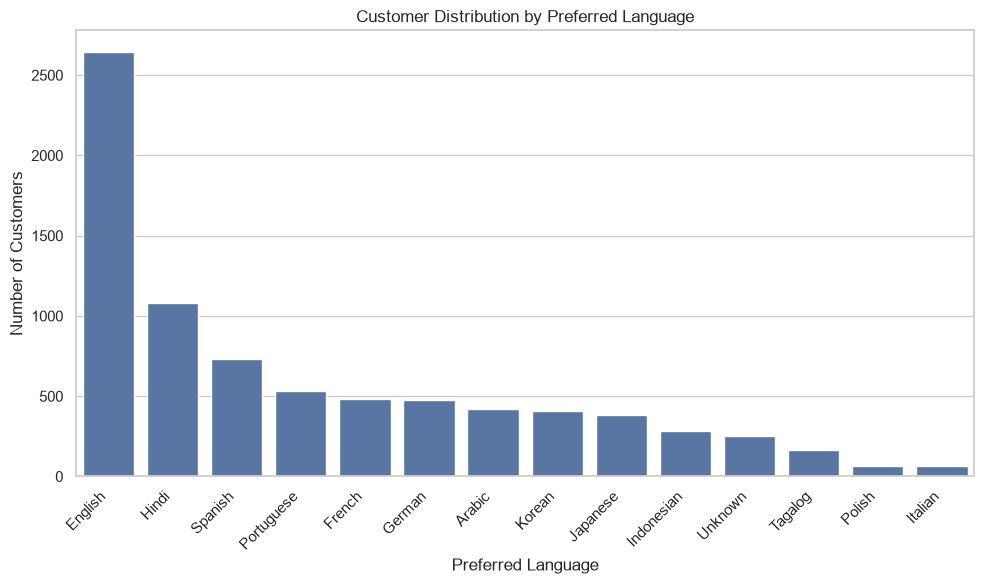

In [ ]:
# Visualization 6 – Customer Preferred Language Distribution.
language_counts = (
    cleaned_datasets["customers"]["preferred_language"]
    .value_counts()
    .reset_index()
)

language_counts.columns = ["preferred_language", "customer_count"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=language_counts,
    x="preferred_language",
    y="customer_count"
)

plt.title("Customer Distribution by Preferred Language")
plt.xlabel("Preferred Language")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

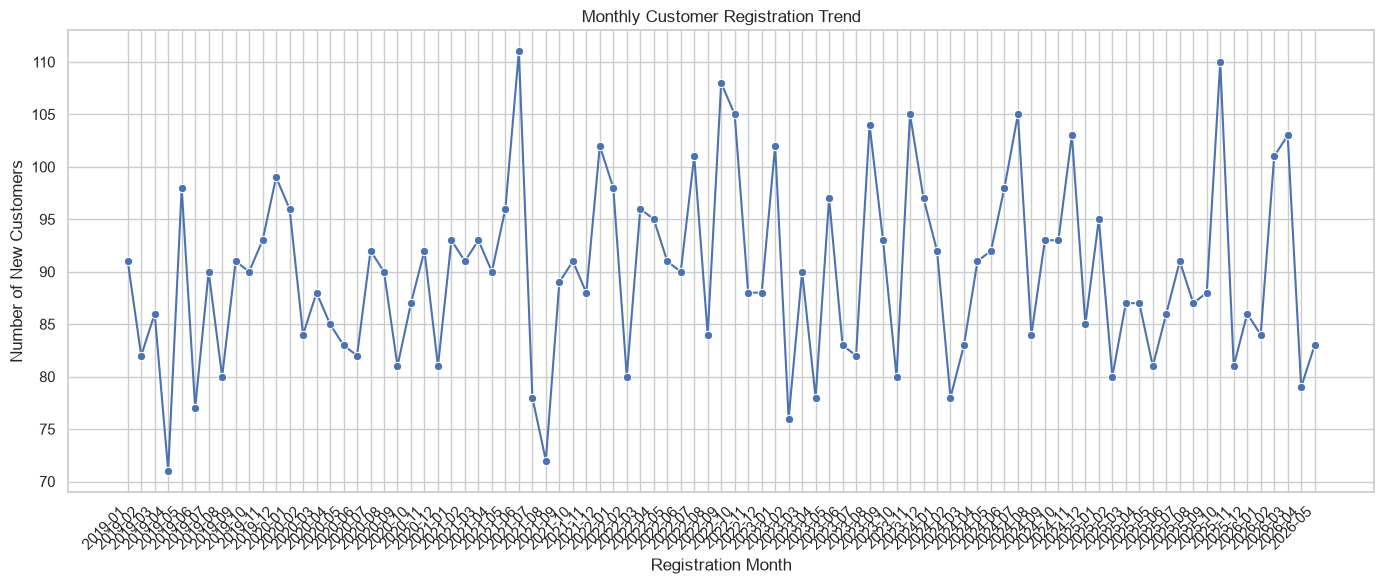

In [15]:
# visualization 7 – Monthly Customer Registration Trend.
registration_dates = pd.to_datetime(
    cleaned_datasets["customers"]["registration_date"],
    errors="coerce"
)

monthly_registrations = (
    registration_dates
    .dropna()
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_registrations.index.astype(str),
    y=monthly_registrations.values,
    marker="o"
)

plt.title("Monthly Customer Registration Trend")
plt.xlabel("Registration Month")
plt.ylabel("Number of New Customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

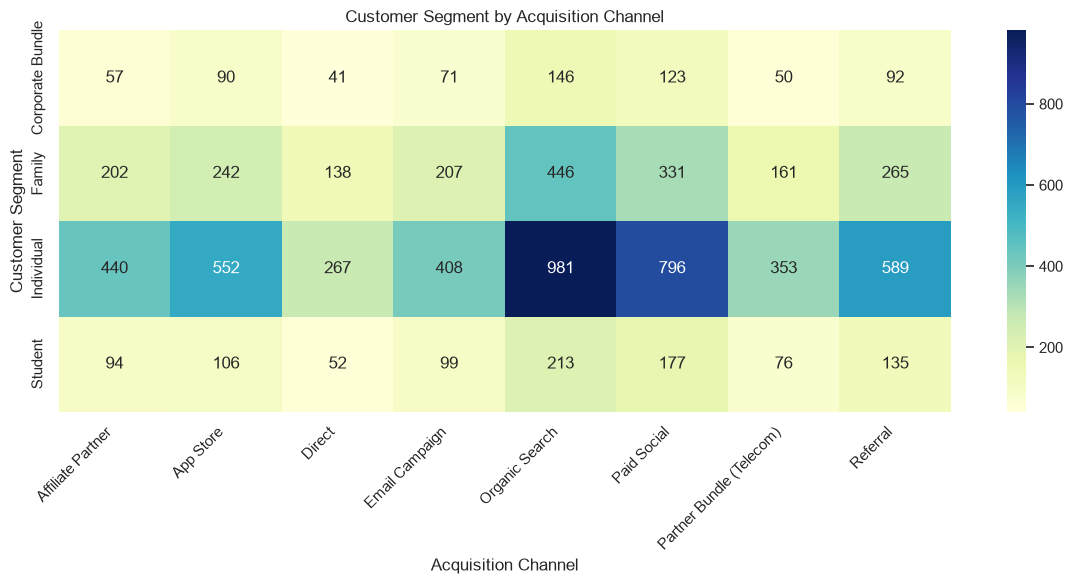

In [17]:
# Visualization 8 – Customer Segment by Acquisition Channel.
segment_channel = pd.crosstab(
    cleaned_datasets["customers"]["customer_segment"],
    cleaned_datasets["customers"]["acquisition_channel"]
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    segment_channel,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Customer Segment by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Customer Segment")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

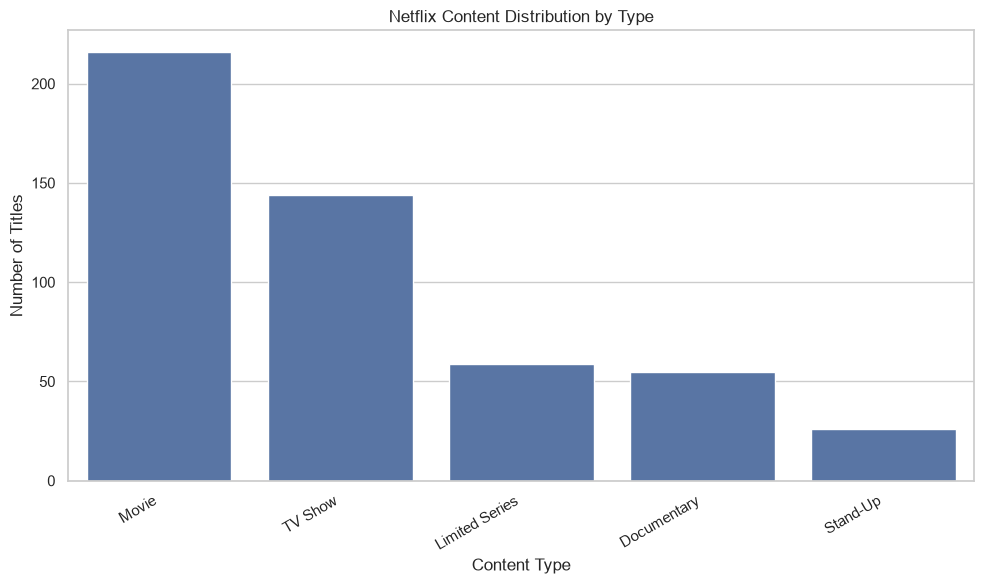

In [ ]:
Visualization 9 – Netflix Content Distribution by Type.
content_type_counts = (
    cleaned_datasets["content"]["content_type"]
    .value_counts()
    .reset_index()
)

content_type_counts.columns = ["content_type", "content_count"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=content_type_counts,
    x="content_type",
    y="content_count"
)

plt.title("Netflix Content Distribution by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

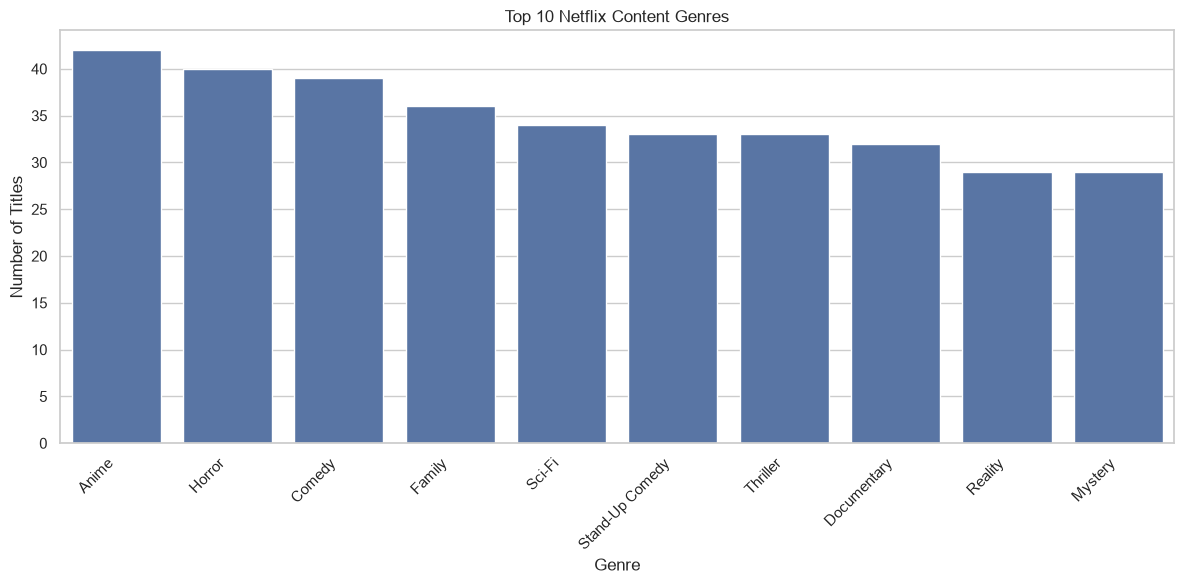

In [19]:
# Visualization 10 – Top 10 Netflix Content Genres.
genre_counts = (
    cleaned_datasets["content"]["genre"]
    .value_counts()
    .head(10)
    .reset_index()
)

genre_counts.columns = ["genre", "content_count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=genre_counts,
    x="genre",
    y="content_count"
)

plt.title("Top 10 Netflix Content Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

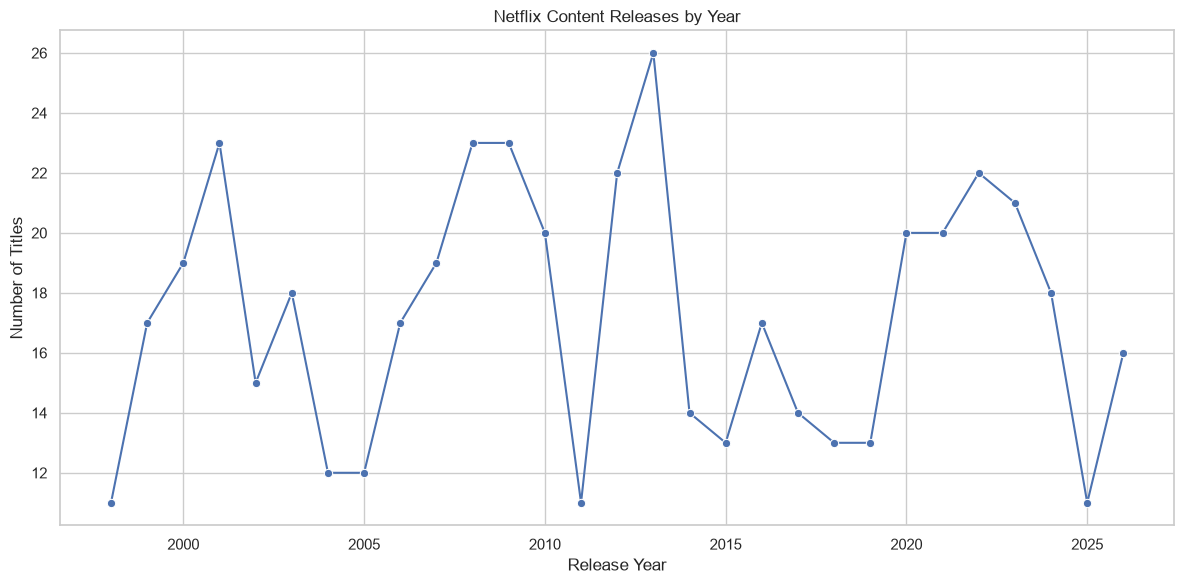

In [21]:
# Visualization 11 – Netflix Content Releases by Year.
content_years = cleaned_datasets["content"].copy()

content_years["release_year"] = pd.to_numeric(
    content_years["release_year"],
    errors="coerce"
)

yearly_content = (
    content_years["release_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_content.index,
    y=yearly_content.values,
    marker="o"
)

plt.title("Netflix Content Releases by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
print(cleaned_datasets["content"].columns.tolist())

['content_id', 'title', 'content_type', 'genre', 'release_year', 'duration_minutes', 'content_language', 'production_country', 'maturity_rating']


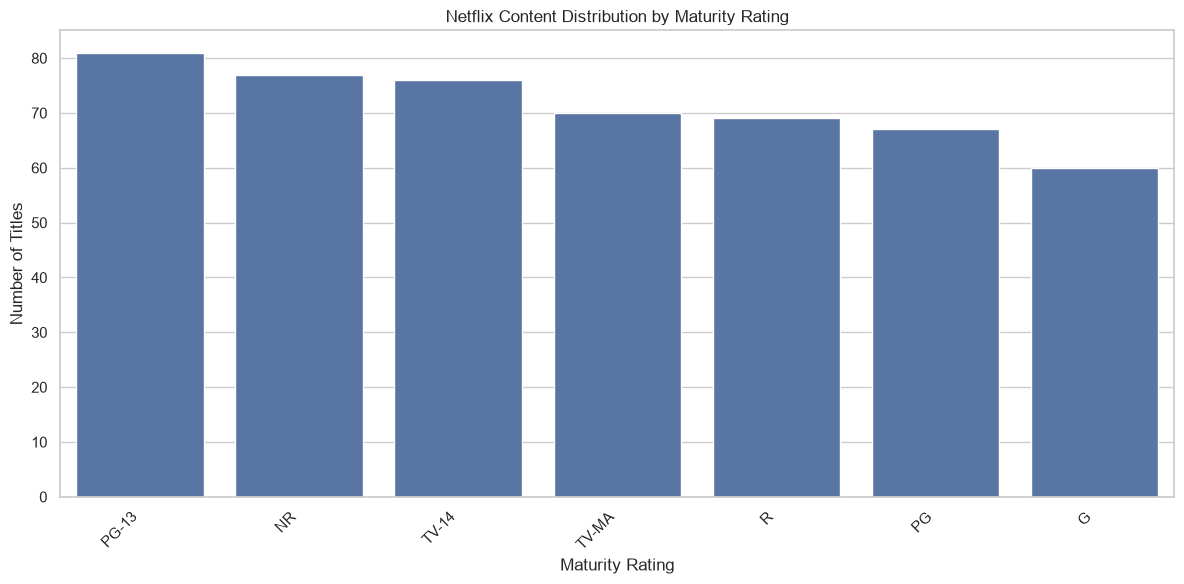

In [26]:
# Visualization 12 – Netflix Content Distribution by Maturity Rating.
rating_counts = (
    cleaned_datasets["content"]["maturity_rating"]
    .value_counts()
    .reset_index()
)

rating_counts.columns = ["maturity_rating", "content_count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=rating_counts,
    x="maturity_rating",
    y="content_count"
)

plt.title("Netflix Content Distribution by Maturity Rating")
plt.xlabel("Maturity Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

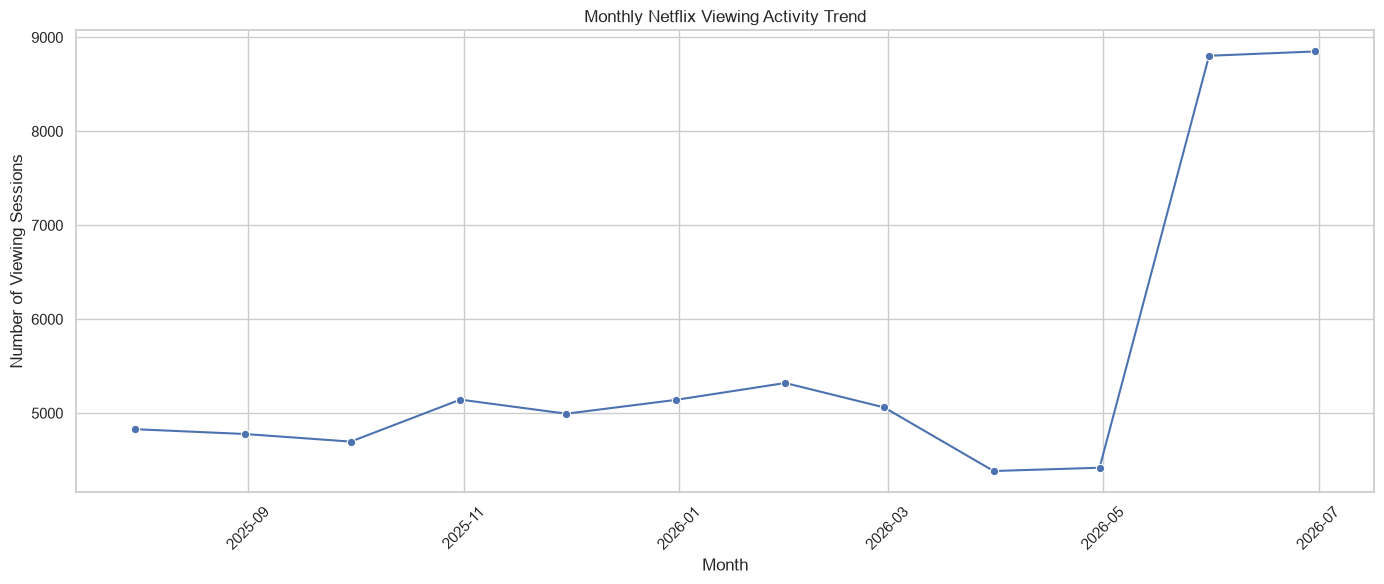

In [28]:
# Visualization 13 – Monthly Netflix Viewing Activity Trend.
viewing_data = cleaned_datasets["viewing_activity"].copy()

viewing_data["viewing_date"] = pd.to_datetime(
    viewing_data["viewing_date"],
    errors="coerce"
)

monthly_views = (
    viewing_data.dropna(subset=["viewing_date"])
    .set_index("viewing_date")
    .resample("ME")
    .size()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_views.index,
    y=monthly_views.values,
    marker="o"
)

plt.title("Monthly Netflix Viewing Activity Trend")
plt.xlabel("Month")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
print(cleaned_datasets["viewing_activity"].columns.tolist())

['viewing_id', 'customer_id', 'content_id', 'viewing_date', 'watch_duration_minutes', 'completion_percentage', 'device_type', 'login_location', 'session_duration_minutes']


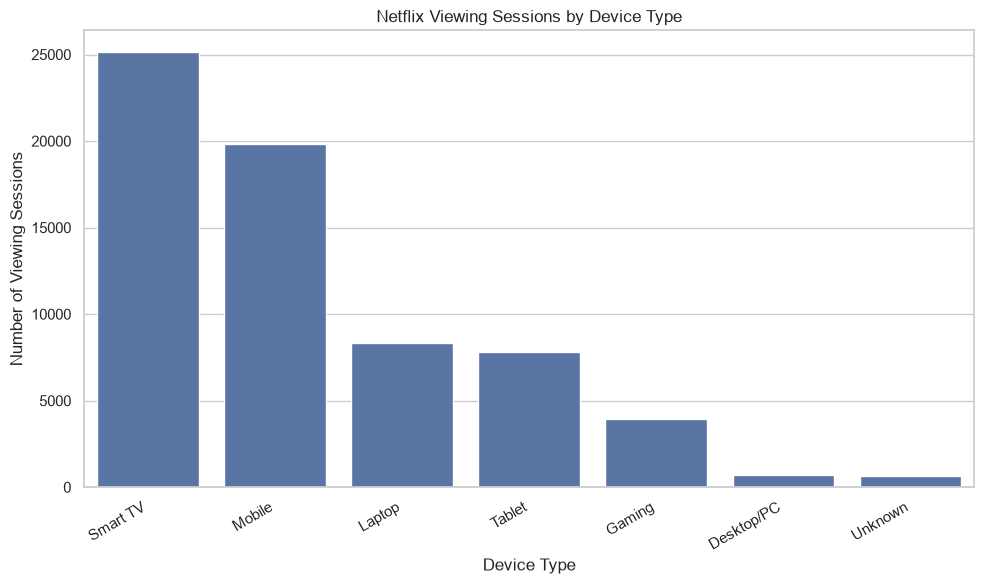

In [31]:
# Visualization 14 – Netflix Viewing Sessions by Device Type.
device_counts = (
    cleaned_datasets["viewing_activity"]["device_type"]
    .value_counts()
    .reset_index()
)

device_counts.columns = ["device_type", "session_count"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=device_counts,
    x="device_type",
    y="session_count"
)

plt.title("Netflix Viewing Sessions by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

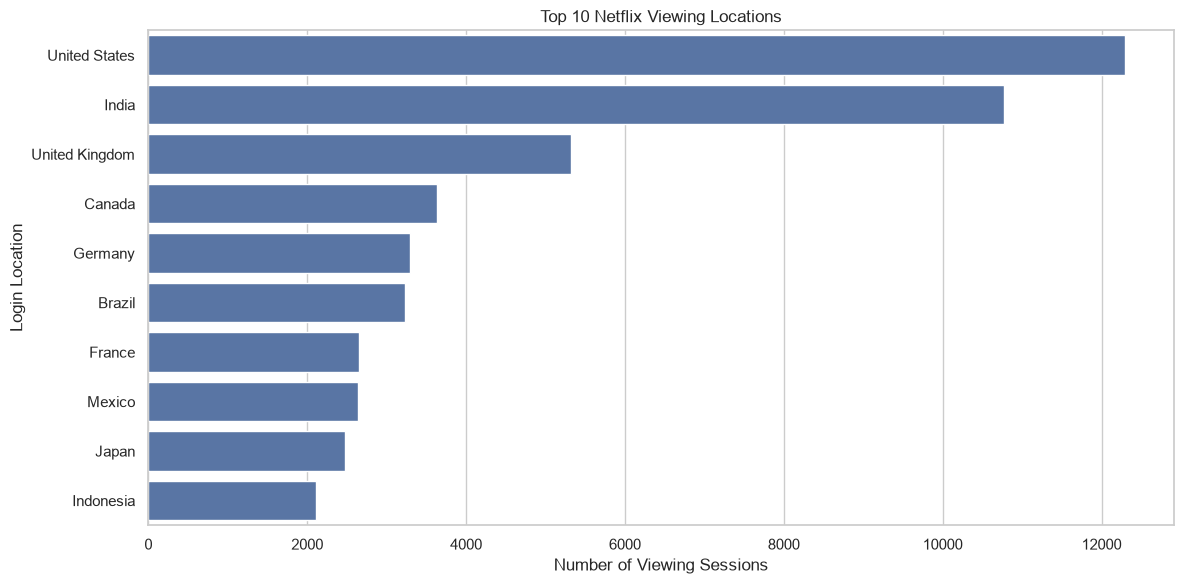

In [32]:
# Visualization 15 – Top 10 Netflix Viewing Locations.
location_counts = (
    cleaned_datasets["viewing_activity"]["login_location"]
    .value_counts()
    .head(10)
    .reset_index()
)

location_counts.columns = ["login_location", "session_count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=location_counts,
    x="session_count",
    y="login_location"
)

plt.title("Top 10 Netflix Viewing Locations")
plt.xlabel("Number of Viewing Sessions")
plt.ylabel("Login Location")
plt.tight_layout()
plt.show()

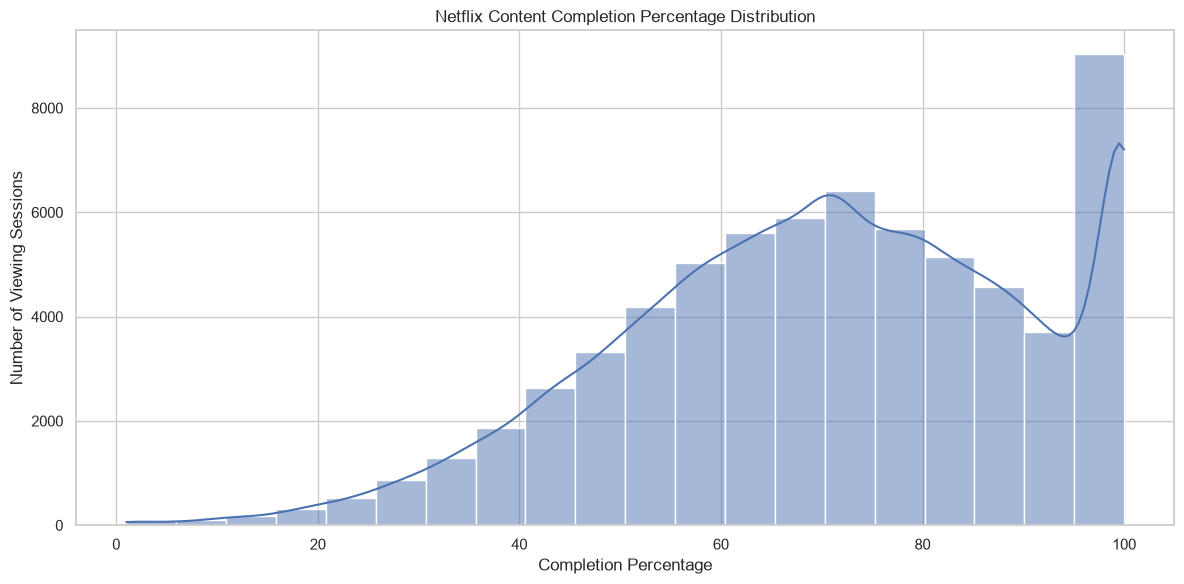

In [33]:
# Visualization 16 – Netflix Content Completion Percentage Distribution.
completion_data = pd.to_numeric(
    cleaned_datasets["viewing_activity"]["completion_percentage"],
    errors="coerce"
).dropna()

plt.figure(figsize=(12, 6))

sns.histplot(
    completion_data,
    bins=20,
    kde=True
)

plt.title("Netflix Content Completion Percentage Distribution")
plt.xlabel("Completion Percentage")
plt.ylabel("Number of Viewing Sessions")
plt.tight_layout()
plt.show()

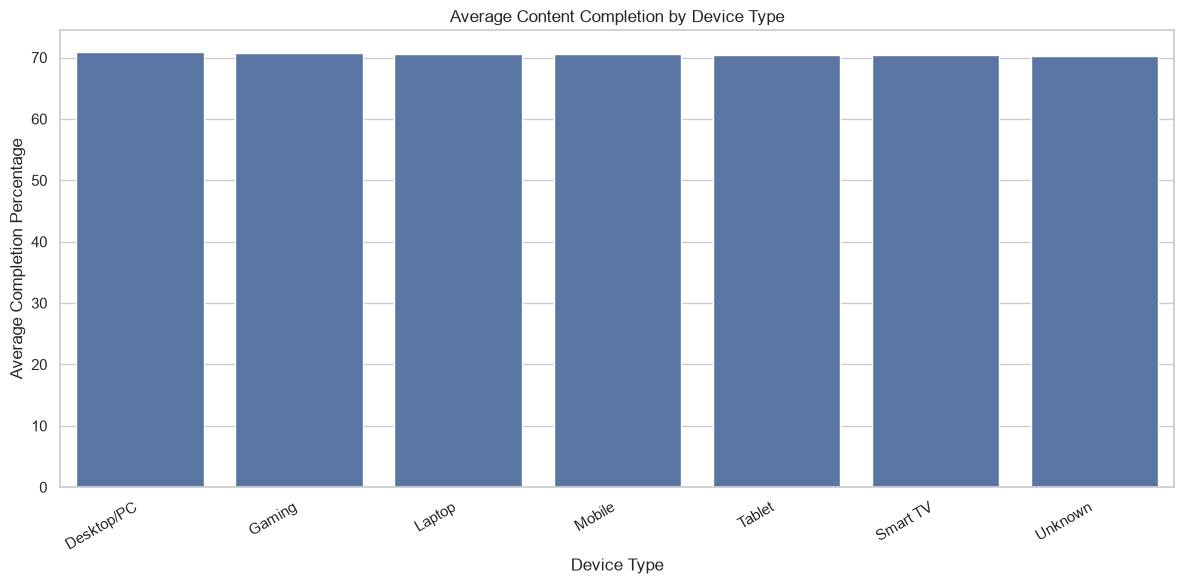

In [34]:
# Visualization 17 – Average Content Completion by Device Type.
device_completion = cleaned_datasets["viewing_activity"].copy()

device_completion["completion_percentage"] = pd.to_numeric(
    device_completion["completion_percentage"],
    errors="coerce"
)

device_avg_completion = (
    device_completion.groupby("device_type")["completion_percentage"]
    .mean()
    .dropna()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=device_avg_completion,
    x="device_type",
    y="completion_percentage"
)

plt.title("Average Content Completion by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Average Completion Percentage")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

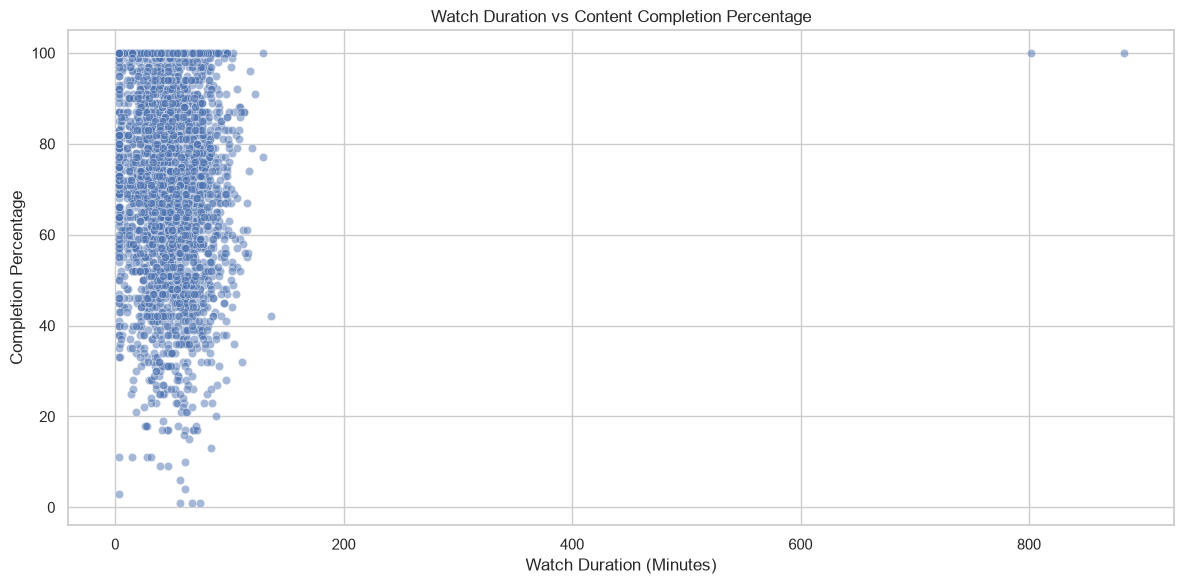

In [ ]:
# Visualization 18 – Watch Duration vs Content Completion Percentage.
viewing_relationship = cleaned_datasets["viewing_activity"].copy()

viewing_relationship["watch_duration_minutes"] = pd.to_numeric(
    viewing_relationship["watch_duration_minutes"],
    errors="coerce"
)

viewing_relationship["completion_percentage"] = pd.to_numeric(
    viewing_relationship["completion_percentage"],
    errors="coerce"
)

viewing_relationship = viewing_relationship.dropna(
    subset=["watch_duration_minutes", "completion_percentage"]
)

viewing_sample = viewing_relationship.sample(
    n=min(3000, len(viewing_relationship)),
    random_state=42
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=viewing_sample,
    x="watch_duration_minutes",
    y="completion_percentage",
    alpha=0.5
)

plt.title("Watch Duration vs Content Completion Percentage")
plt.xlabel("Watch Duration (Minutes)")
plt.ylabel("Completion Percentage")
plt.tight_layout()
plt.show()

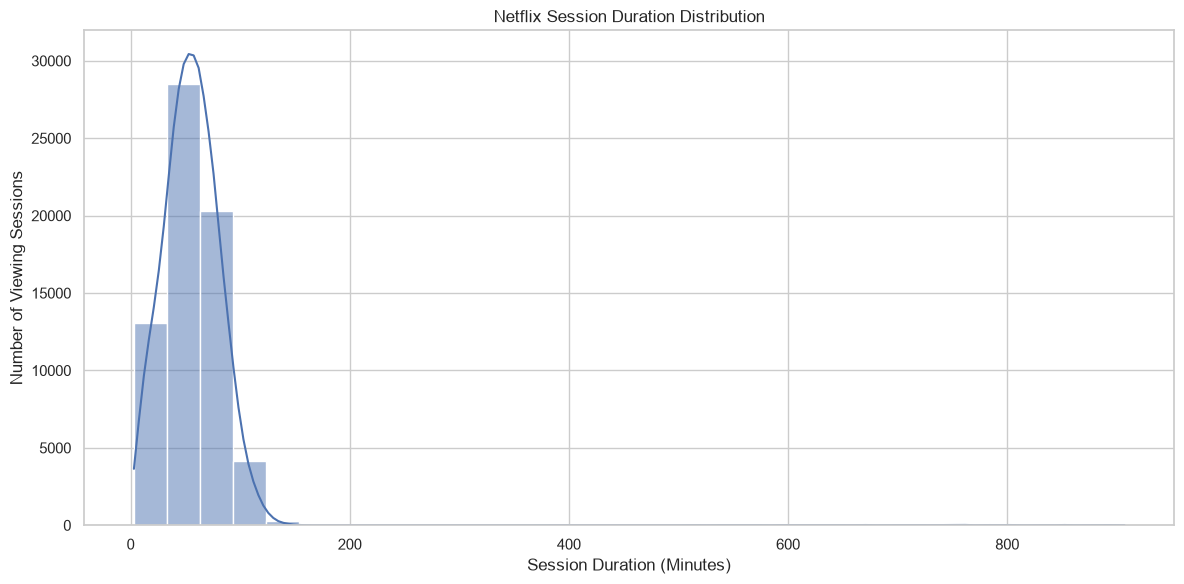

In [36]:
# Visualization 19 – Netflix Session Duration Distribution.
session_duration = pd.to_numeric(
    cleaned_datasets["viewing_activity"]["session_duration_minutes"],
    errors="coerce"
).dropna()

plt.figure(figsize=(12, 6))

sns.histplot(
    session_duration,
    bins=30,
    kde=True
)

plt.title("Netflix Session Duration Distribution")
plt.xlabel("Session Duration (Minutes)")
plt.ylabel("Number of Viewing Sessions")
plt.tight_layout()
plt.show()

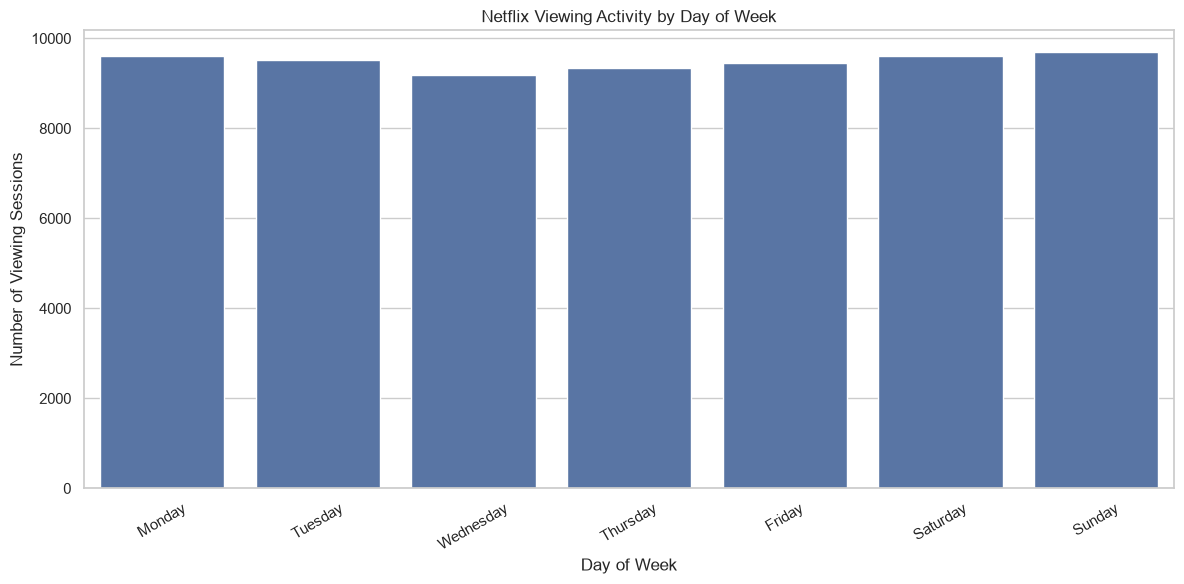

In [37]:
# Visualization 20 – Netflix Viewing Activity by Day of Week.
viewing_days = cleaned_datasets["viewing_activity"].copy()

viewing_days["viewing_date"] = pd.to_datetime(
    viewing_days["viewing_date"],
    errors="coerce"
)

viewing_days["day_of_week"] = viewing_days["viewing_date"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_counts = (
    viewing_days["day_of_week"]
    .value_counts()
    .reindex(day_order, fill_value=0)
    .reset_index()
)

day_counts.columns = ["day_of_week", "session_count"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=day_counts,
    x="day_of_week",
    y="session_count",
    order=day_order
)

plt.title("Netflix Viewing Activity by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

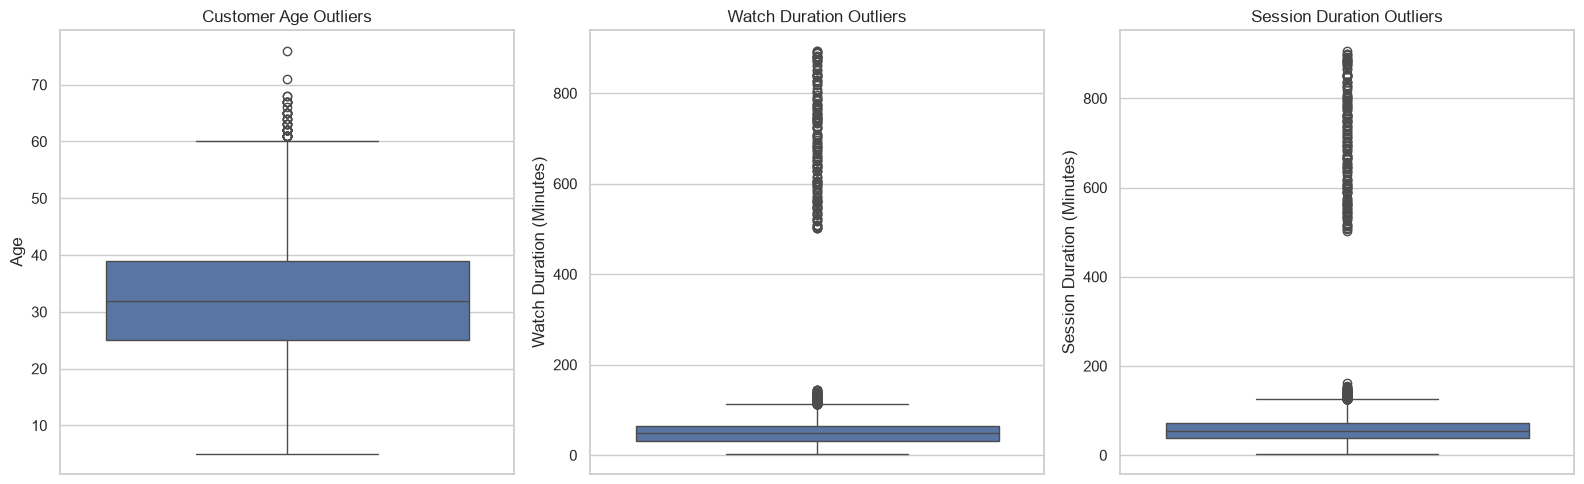

In [38]:
# Visualization 21 – Outlier Detection in Customer Age, Watch Duration, and Session Duration.
customers_age = pd.to_numeric(
    cleaned_datasets["customers"]["age"],
    errors="coerce"
).dropna()

watch_duration = pd.to_numeric(
    cleaned_datasets["viewing_activity"]["watch_duration_minutes"],
    errors="coerce"
).dropna()

session_duration = pd.to_numeric(
    cleaned_datasets["viewing_activity"]["session_duration_minutes"],
    errors="coerce"
).dropna()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(y=customers_age, ax=axes[0], showfliers=True)
axes[0].set_title("Customer Age Outliers")
axes[0].set_ylabel("Age")

sns.boxplot(y=watch_duration, ax=axes[1], showfliers=True)
axes[1].set_title("Watch Duration Outliers")
axes[1].set_ylabel("Watch Duration (Minutes)")

sns.boxplot(y=session_duration, ax=axes[2], showfliers=True)
axes[2].set_title("Session Duration Outliers")
axes[2].set_ylabel("Session Duration (Minutes)")

plt.tight_layout()
plt.show()

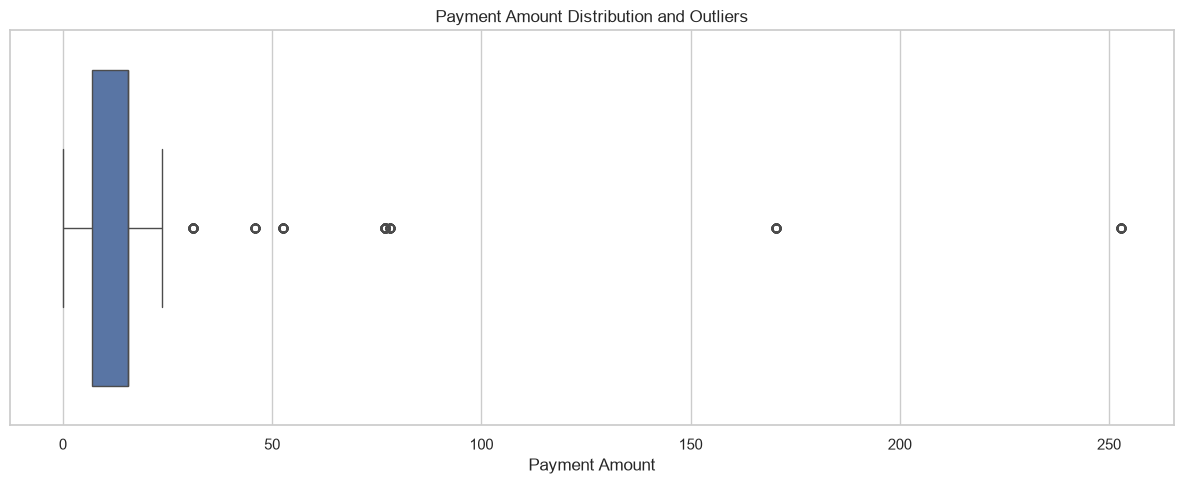

In [ ]:
Visualization 22 – Outlier Detection in Payment Amounts.
payment_amounts = pd.to_numeric(
    cleaned_datasets["payments"]["amount"],
    errors="coerce"
).dropna()

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=payment_amounts,
    showfliers=True
)

plt.title("Payment Amount Distribution and Outliers")
plt.xlabel("Payment Amount")
plt.tight_layout()
plt.show()

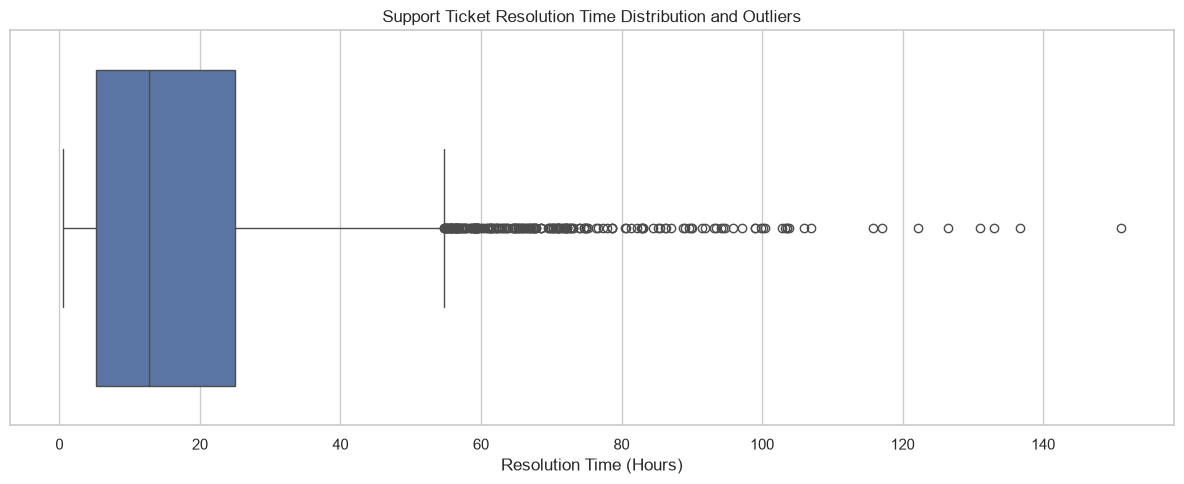

In [40]:
# Visualization 23 – Outlier Detection in Support Ticket Resolution Times.
resolution_times = pd.to_numeric(
    cleaned_datasets["support_tickets"]["resolution_time_hours"],
    errors="coerce"
).dropna()

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=resolution_times,
    showfliers=True
)

plt.title("Support Ticket Resolution Time Distribution and Outliers")
plt.xlabel("Resolution Time (Hours)")
plt.tight_layout()
plt.show()